# The Functional API

Each functional generator returns an array of length $\lceil T/dt \rceil$ (or shape `(steps, n)` for `n` independent channels). This tutorial goes through all of them, grouped by family, and checks each against what its parameters promise.

| Family | Functions |
|---|---|
| Piecewise | `section`, `constant`, `step`, `ramp` |
| Periodic | `sinusoidal`, `square`, `triangular`, `sawtooth`, `chirp`, `noisy_sinusoidal` |
| Pulses | `spike`, `gaussian_pulse`, `exponential_decay`, `double_exponential`, `burst` |
| Stochastic | `wiener_process`, `ou_process`, `poisson` |

The composable classes take the same parameters, but some are in a **different positional order** (for example `spike(sp_times, sp_lens, sp_sizes, duration)` versus `Spike(sp_times, duration, sp_lens, sp_sizes)`). Passing parameters by keyword avoids mistakes when switching between the two.

## 1. Setup

In [1]:
import brainstate
import brainunit as u
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal as sps

import braintools.input as inp

brainstate.environ.set(dt=0.1 * u.ms)
dt_ms = 0.1


def t_of(x):
    return np.arange(len(x)) * dt_ms


def show(panels, ncols=2, height=2.2):
    # Plot a dict {title: array} on a grid.
    nrows = int(np.ceil(len(panels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, height * nrows), squeeze=False)
    for ax, (title, x) in zip(axes.flat, panels.items()):
        ax.plot(t_of(x), u.get_mantissa(x), lw=1)
        ax.set_title(title, fontsize=10)
    for ax in axes.flat[len(panels):]:
        ax.axis("off")
    for ax in axes[-1]:
        ax.set_xlabel("time (ms)")
    fig.tight_layout()
    plt.show()

## 2. Piecewise Signals

- `section(values, durations)` concatenates constant segments; each value lasts for its duration.
- `constant([(value, duration), ...])` does the same from pairs, and returns a tuple `(array, total_duration)`.
- `step(amplitudes, step_times, duration)` sets each amplitude from its **start time** until the next start time. Times are sorted first.
- `ramp(c_start, c_end, duration, t_start=None, t_end=None)` goes linearly from `c_start` to `c_end` between `t_start` and `t_end` and is 0 outside that window.

constant returns total duration: 100 ms
section == constant == step: True
ramp is 0 before 20 ms: True, reaches 1.000 nA at 80 ms, then 0: True


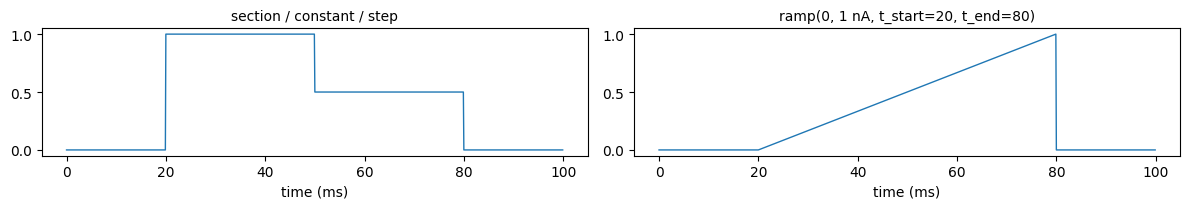

In [2]:
sec = inp.section([0, 1, 0.5, 0] * u.nA, [20, 30, 30, 20] * u.ms)
const, total = inp.constant([(0 * u.nA, 20 * u.ms), (1 * u.nA, 30 * u.ms), (0.5 * u.nA, 30 * u.ms), (0 * u.nA, 20 * u.ms)])
stp = inp.step([0, 1, 0.5, 0] * u.nA, [0, 20, 50, 80] * u.ms, duration=100 * u.ms)
rmp = inp.ramp(0 * u.nA, 1 * u.nA, 100 * u.ms, t_start=20 * u.ms, t_end=80 * u.ms)

print("constant returns total duration:", total)
print("section == constant == step:", bool(u.math.allclose(sec, const)) and bool(u.math.allclose(sec, stp)))
print(f"ramp is 0 before 20 ms: {float(rmp[199].to_decimal(u.nA)) == 0.0}, "
      f"reaches {float(rmp[799].to_decimal(u.nA)):.3f} nA at 80 ms, then 0: {float(rmp[800].to_decimal(u.nA)) == 0.0}")
show({"section / constant / step": sec, "ramp(0, 1 nA, t_start=20, t_end=80)": rmp})

## 3. Periodic Signals

All periodic generators take `amplitude`, `frequency`, and `duration`, and optionally `t_start` / `t_end` (the signal is 0 outside the window and starts at phase 0 at `t_start`).

- `sinusoidal`, `square`, `triangular`, `sawtooth` oscillate between `-amplitude` and `+amplitude`; `square` has a `duty_cycle` (fraction of each period at `+amplitude`).
- `bias=True` adds `amplitude`, so the signal runs from 0 to `2 * amplitude`.
- `chirp(amplitude, f_start, f_end, duration, method='linear' | 'logarithmic')` sweeps the frequency.
- `noisy_sinusoidal(amplitude, frequency, noise_amplitude, duration, seed=...)` adds independent Gaussian noise with standard deviation `noise_amplitude` to every sample.

The checks below measure the frequency from rising zero crossings and compare the chirp with `scipy.signal.chirp`.

sinusoidal               frequency  10.00 Hz, range [-1.00, 1.00]
square, duty_cycle=0.3   frequency  10.00 Hz, range [-1.00, 1.00]
triangular               frequency  10.00 Hz, range [-1.00, 1.00]
sawtooth                 frequency  10.00 Hz, range [-1.00, 1.00]
square fraction of time high: 0.300
bias=True range: [0.00, 2.00]
chirp linear      max |difference| from scipy: 3.0e-08
chirp logarithmic max |difference| from scipy: 3.0e-08
noisy_sinusoidal residual std: 0.296 (noise_amplitude 0.3)


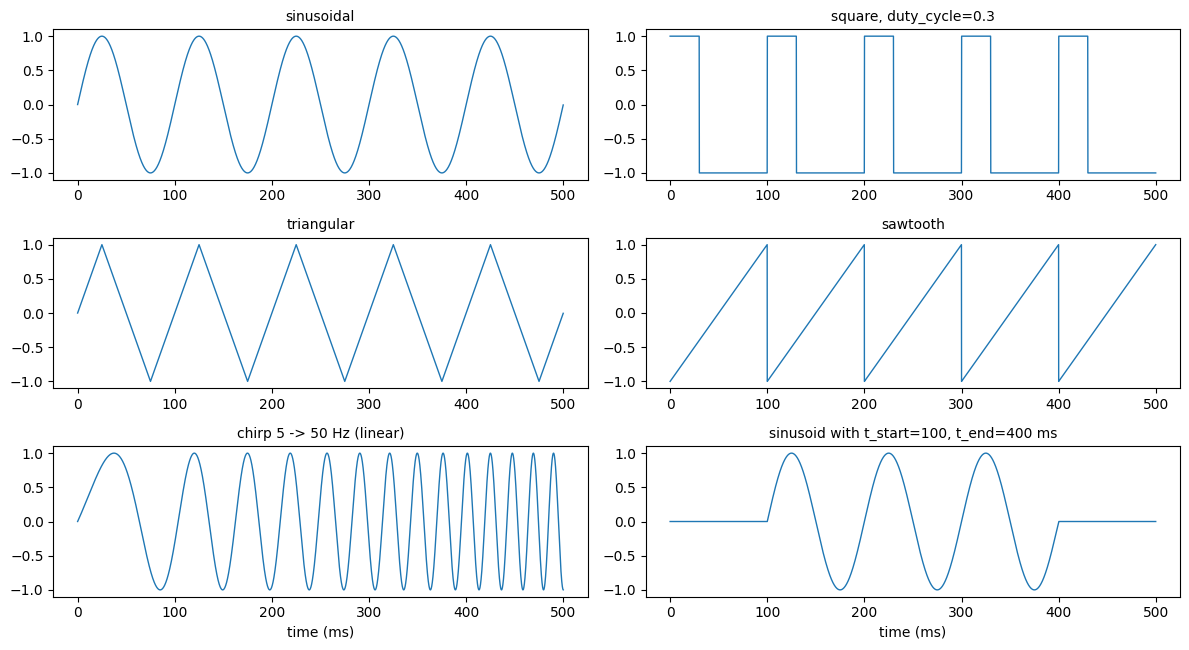

In [3]:
def measured_frequency(x):
    y = np.asarray(x) - np.mean(x)
    up = np.flatnonzero((y[:-1] < 0) & (y[1:] >= 0))
    return (len(up) - 1) / ((up[-1] - up[0]) * dt_ms * 1e-3)


periodic = {
    "sinusoidal": inp.sinusoidal(1.0, 10 * u.Hz, 500 * u.ms),
    "square, duty_cycle=0.3": inp.square(1.0, 10 * u.Hz, 500 * u.ms, duty_cycle=0.3),
    "triangular": inp.triangular(1.0, 10 * u.Hz, 500 * u.ms),
    "sawtooth": inp.sawtooth(1.0, 10 * u.Hz, 500 * u.ms),
}
for name, x in periodic.items():
    print(f"{name:24s} frequency {measured_frequency(x):6.2f} Hz, range [{x.min():.2f}, {x.max():.2f}]")
sq = periodic["square, duty_cycle=0.3"]
print(f"square fraction of time high: {np.mean(sq > 0):.3f}")
biased = inp.sinusoidal(1.0, 10 * u.Hz, 500 * u.ms, bias=True)
print(f"bias=True range: [{biased.min():.2f}, {biased.max():.2f}]")

t_sec = np.arange(10000) * dt_ms * 1e-3
for method in ["linear", "logarithmic"]:
    ch = np.asarray(inp.chirp(1.0, 5 * u.Hz, 50 * u.Hz, 1000 * u.ms, method=method))
    ref = sps.chirp(t_sec, 5, 1.0, 50, method=method, phi=-90)  # phi=-90 turns scipy's cosine into a sine
    print(f"chirp {method:11s} max |difference| from scipy: {np.abs(ch - ref).max():.1e}")

noisy = inp.noisy_sinusoidal(1.0, 10 * u.Hz, 0.3, 500 * u.ms, seed=0)
print(f"noisy_sinusoidal residual std: {np.std(noisy - periodic['sinusoidal']):.3f} (noise_amplitude 0.3)")

show({**periodic,
      "chirp 5 -> 50 Hz (linear)": inp.chirp(1.0, 5 * u.Hz, 50 * u.Hz, 500 * u.ms),
      "sinusoid with t_start=100, t_end=400 ms": inp.sinusoidal(1.0, 10 * u.Hz, 500 * u.ms, t_start=100 * u.ms, t_end=400 * u.ms)})

## 4. Pulses

- `spike(sp_times, sp_lens, sp_sizes, duration)`: rectangular pulses starting at `sp_times`; `sp_lens` and `sp_sizes` may be a single value or one per pulse.
- `gaussian_pulse(amplitude, center, sigma, duration)`: peak value `amplitude` at `center`.
- `exponential_decay(amplitude, tau, duration, t_start=None)`: jumps to `amplitude` at `t_start` and decays as $e^{-(t - t_{start})/\tau}$.
- `double_exponential(amplitude, tau_rise, tau_decay, duration, t_start=None)`: the difference of two exponentials, **normalized so its peak equals `amplitude`**; the peak occurs $\frac{\tau_r \tau_d}{\tau_d - \tau_r}\ln\frac{\tau_d}{\tau_r}$ after `t_start`.
- `burst(burst_amp, burst_freq, burst_duration, inter_burst_interval, n_bursts, duration)`: `n_bursts` windows of length `burst_duration`, separated by `inter_burst_interval`, each filled with a sinusoid of frequency `burst_freq` that starts at phase 0. For a train of rectangular pulses use `spike` or `square` instead.

spike pulse widths (samples): [10, 20, 50]
gaussian peak 1.000 at 50.0 ms
exponential_decay at t_start + tau: 0.3679 (exp(-1) = 0.3679)
double_exponential peak 1.000 at 2.6 ms after onset (theory 2.56 ms)
burst is non-zero between 0.1 and 69.9 ms (bursts at 0-20 and 50-70 ms)


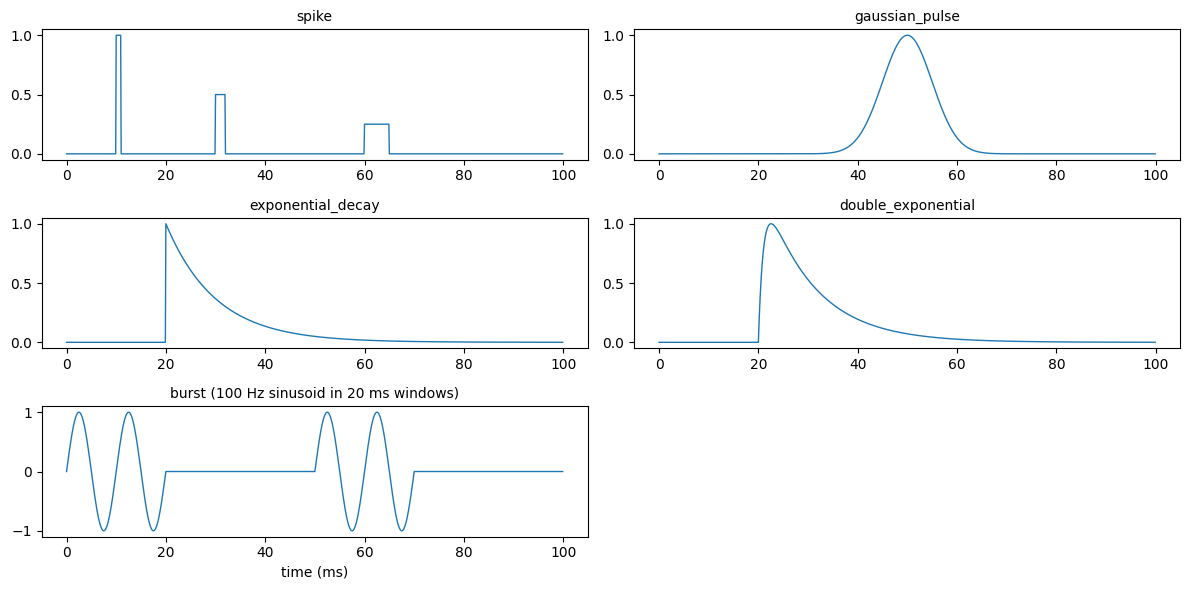

In [4]:
spk = inp.spike(sp_times=[10, 30, 60] * u.ms, sp_lens=[1, 2, 5] * u.ms, sp_sizes=[1.0, 0.5, 0.25], duration=100 * u.ms)
gau = inp.gaussian_pulse(1.0, center=50 * u.ms, sigma=5 * u.ms, duration=100 * u.ms)
exd = inp.exponential_decay(1.0, tau=10 * u.ms, duration=100 * u.ms, t_start=20 * u.ms)
dex = inp.double_exponential(1.0, tau_rise=1 * u.ms, tau_decay=10 * u.ms, duration=100 * u.ms, t_start=20 * u.ms)
bur = inp.burst(burst_amp=1.0, burst_freq=100 * u.Hz, burst_duration=20 * u.ms,
                inter_burst_interval=30 * u.ms, n_bursts=2, duration=100 * u.ms)

print("spike pulse widths (samples):", [int(np.sum(np.asarray(spk) == v)) for v in (1.0, 0.5, 0.25)])
print(f"gaussian peak {gau.max():.3f} at {t_of(gau)[np.argmax(gau)]:.1f} ms")
print(f"exponential_decay at t_start + tau: {exd[300]:.4f} (exp(-1) = {np.exp(-1):.4f})")
t_peak = 1 * 10 / (10 - 1) * np.log(10 / 1)
print(f"double_exponential peak {dex.max():.3f} at {t_of(dex)[np.argmax(dex)] - 20:.1f} ms after onset (theory {t_peak:.2f} ms)")
on = np.flatnonzero(np.abs(np.asarray(bur)) > 0) * dt_ms
print(f"burst is non-zero between {on[0]:.1f} and {on[-1]:.1f} ms (bursts at 0-20 and 50-70 ms)")

show({"spike": spk, "gaussian_pulse": gau, "exponential_decay": exd,
      "double_exponential": dex, "burst (100 Hz sinusoid in 20 ms windows)": bur}, height=2.0)

## 5. Stochastic Processes

All three accept `seed` for reproducibility and `n` for independent channels (output shape `(steps, n)`).

- **`ou_process(mean, sigma, tau, duration)`**: an Ornstein-Uhlenbeck process, i.e. noise with correlation time `tau`. It starts at `mean`, and **`sigma` is its stationary standard deviation**; the autocorrelation decays as $e^{-|\text{lag}|/\tau}$. The update is exact, so the statistics do not depend on `dt` or on the time unit.
- **`wiener_process(duration, sigma)`**: the **increments** $dW \sim \mathcal N(0, \sigma^2 dt)$ of a Wiener process, one independent sample per step. This is white noise, not the Brownian path $W(t)$ (use `cumsum` for the path). `dt` enters as its number in the unit it was set with, so keep the time unit consistent when choosing `sigma`.
- **`poisson(rate, duration, amplitude=1)`**: in each step an event occurs with probability `rate * dt`, and the output is `amplitude` on event steps and 0 elsewhere.

In [5]:
ou = np.asarray(inp.ou_process(mean=0.5, sigma=0.2, tau=10 * u.ms, duration=20_000 * u.ms, n=8, seed=0))
x = ou[2000:] - ou[2000:].mean(axis=0)
lag = 100  # 10 ms
rho = np.mean(x[:-lag] * x[lag:], axis=0) / np.var(x, axis=0)
print(f"OU (8 channels): mean {ou.mean():.3f} (0.5), std {ou.std(axis=0).mean():.3f} (0.2), "
      f"autocorrelation at lag tau {rho.mean():.3f} (exp(-1) = {np.exp(-1):.3f})")

dw = inp.wiener_process(duration=20_000 * u.ms, sigma=2.0, seed=0)
print(f"Wiener increments: std {np.std(dw):.4f} (sigma*sqrt(dt) = {2.0 * np.sqrt(dt_ms):.4f}), "
      f"lag-1 correlation {np.corrcoef(dw[:-1], dw[1:])[0, 1]:+.3f}")

pois = inp.poisson(rate=20 * u.Hz, duration=1000 * u.ms, n=200, seed=0)
counts = np.asarray(pois).sum(axis=0)
event_times = [np.flatnonzero(col) * dt_ms for col in np.asarray(pois).T]
isis = np.concatenate([np.diff(e) for e in event_times])
print(f"Poisson 20 Hz over 1 s, 200 channels: mean count {counts.mean():.2f} (20), "
      f"Fano factor {counts.var() / counts.mean():.2f} (1), ISI CV {isis.std() / isis.mean():.2f} (1)")

OU (8 channels): mean 0.503 (0.5), std 0.199 (0.2), autocorrelation at lag tau 0.367 (exp(-1) = 0.368)
Wiener increments: std 0.6312 (sigma*sqrt(dt) = 0.6325), lag-1 correlation -0.001
Poisson 20 Hz over 1 s, 200 channels: mean count 19.97 (20), Fano factor 1.03 (1), ISI CV 1.00 (1)


The OU std, the Wiener increment std, and the Poisson statistics all match their definitions. The figure shows OU processes with different correlation times (same seed), a Wiener increment trace with its cumulative path, and a Poisson raster.

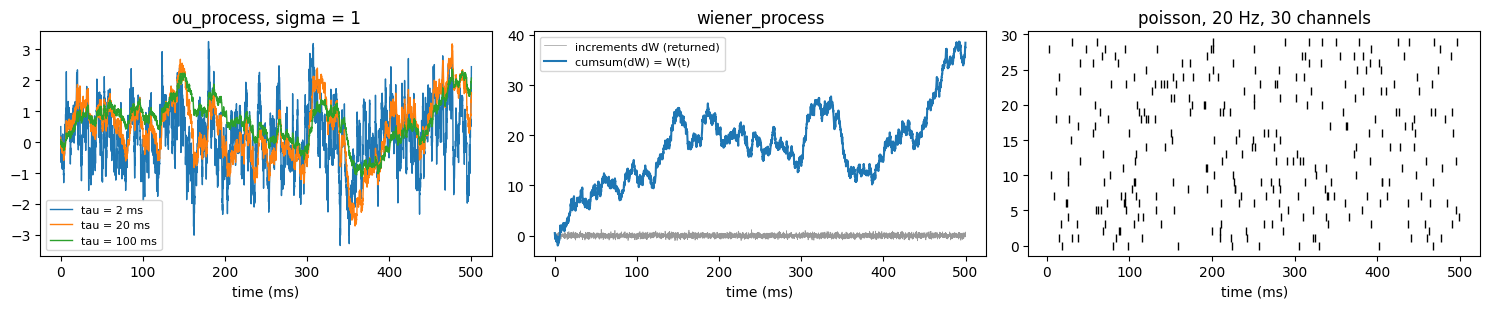

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for tau in [2, 20, 100]:
    trace = inp.ou_process(mean=0.0, sigma=1.0, tau=tau * u.ms, duration=500 * u.ms, seed=1)
    axes[0].plot(t_of(trace), trace, lw=1, label=f"tau = {tau} ms")
axes[0].set_title("ou_process, sigma = 1")
axes[0].legend(fontsize=8)

dw = inp.wiener_process(duration=500 * u.ms, sigma=1.0, seed=1)
axes[1].plot(t_of(dw), dw, lw=0.5, color="0.6", label="increments dW (returned)")
axes[1].plot(t_of(dw), np.cumsum(dw), lw=1.5, label="cumsum(dW) = W(t)")
axes[1].set_title("wiener_process")
axes[1].legend(fontsize=8)

raster = np.asarray(inp.poisson(rate=20 * u.Hz, duration=500 * u.ms, n=30, seed=2))
rows, cols = np.nonzero(raster.T)
axes[2].plot(cols * dt_ms, rows, "|", ms=6, color="k")
axes[2].set_title("poisson, 20 Hz, 30 channels")
for ax in axes:
    ax.set_xlabel("time (ms)")
fig.tight_layout()
plt.show()

## 6. Assembling a Protocol from Arrays

Functional outputs are ordinary arrays, so a protocol can be assembled with `u.math.concatenate` (segments one after another) and `+` (overlays of equal length). The composable API in the next tutorial does the same with less bookkeeping.

8000 samples = 800 ms, unit nA


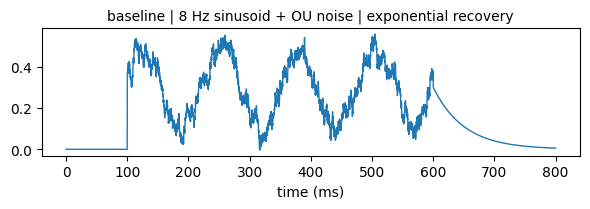

In [7]:
baseline = inp.section([0] * u.nA, [100 * u.ms])
drive = inp.sinusoidal(0.2 * u.nA, 8 * u.Hz, 500 * u.ms) + inp.ou_process(0.3 * u.nA, 0.05 * u.nA, 5 * u.ms, 500 * u.ms, seed=0)
recovery = inp.exponential_decay(0.3 * u.nA, tau=50 * u.ms, duration=200 * u.ms)

protocol = u.math.concatenate([baseline, drive, recovery])
print(f"{protocol.shape[0]} samples = {protocol.shape[0] * dt_ms:.0f} ms, unit {u.get_unit(protocol)}")
show({"baseline | 8 Hz sinusoid + OU noise | exponential recovery": protocol}, ncols=1)

## Summary

- Piecewise: `section` and `constant` take durations, `step` takes start times, `ramp` takes a window.
- Periodic generators share `amplitude`, `frequency`, `t_start`/`t_end`, and `bias`; `chirp` matches `scipy.signal.chirp`.
- `double_exponential` is peak-normalized; `burst` fills its windows with a sinusoid.
- `ou_process(sigma=...)` sets the stationary standard deviation; `wiener_process` returns increments with std $\sigma\sqrt{dt}$; `poisson` places events with probability `rate * dt` per step.
- Use keyword arguments: several functional and composable signatures order their parameters differently.